# Same as linear_testing_2.ipynb, but fitting the pseudo-scores with each TS

In [ ]:
from astropy.io import fits

import numpy as np
import matplotlib.pyplot as plt

from scipy.io import readsav
from sklearn.decomposition import PCA

import tools as t

## Load data

In [2]:
# load files
path_data = '../data/sim_series/'  # directory where the files are saved
N_files = 20  # 20 time series (from 0 to 19)
data_spectra = []
data_rv = []

for i in range(N_files):  # files have the same name, only number changes
    data_spectra.append(fits.getdata(path_data + f'flux_norm_6173_lionel_tau1_spatialscaling1_sansrotation_serie{i}.fits'))
    data_rv.append(readsav(path_data + f'res_rv_bis_6173_lionel_tau1_scaling1_sansrot_serie{i}.sav'))

data_spectra = np.array(data_spectra)
data_rv = np.array(data_rv)
print(data_rv[0].keys())

dict_keys(['rv_gauss', 'rv_correl', 'rv_deriv', 'xbiss', 'ybiss', 'l_true', 'lambd', 'flux_moy'])


In [3]:
c = 3e8  # speed of light [m/s]
# extract data
wl = np.array(data_rv[0]['lambd'])  # same wavelength grid for all time series
times = np.arange(0, len(data_spectra[0]) * 144, 144) / 60 / 24  # time in days, same for all time series
times_sec = times * 86400  # time in sec
# extract wavelength data
wl = np.array(wl)

## Work with only one TS

In [4]:
# selecting TS
ts_index = 0
spectra_ex = data_spectra[ts_index]

# splitting the selected TS in two halves
N = len(times)
N_half = N // 2

times_half = times[:N_half]

spectra_0 = spectra_ex[:N_half]  # first half, 70% for training and 30% for testing
spectra_1 = spectra_ex[N_half:]  # second half, for testing

## Preprocessing

In [5]:
# calculating the mean spectra
mean_spec_0 = np.mean(spectra_0, axis=0)
mean_spec_1 = np.mean(spectra_1, axis=0)

# derivatives of the mean spectra
d_S0 = np.gradient(mean_spec_0, wl)
d_S1 = np.gradient(mean_spec_1, wl)

In [6]:
# subtracting the Doppler vector
Sf_0, D_0 = t.subtract_D(wl, spectra_0, c=c)  # S_f and Doppler vector
Sf_1, D_1 = t.subtract_D(wl, spectra_1, c=c)

# double centering
spectra_centered_0 = t.double_centering(Sf_0)
spectra_centered_1 = t.double_centering(Sf_1)

In [7]:
# preprocessing all TS
mean_spec = np.array([np.mean(i, axis=0) for i in data_spectra])  # list of mean spectrum for each TS
d_S0 = np.array([np.gradient(i, wl) for i in mean_spec])          # list of derivative of the mean spectrum for each TS

S_f = []        # array of matrices
D_vectors = []  # array of Doppler vectors

for i in range(N_files):  # iterate over TS
    s, v = t.subtract_D(wl, data_spectra[i], c=c)  # returns S_f and Doppler vector
    S_f.append(s)
    D_vectors.append(v)

S_f = np.array(S_f)
D_vectors = np.array(D_vectors)

# double centering
spectra_centered = np.array([t.double_centering(i) for i in S_f])

## Calculate RV by template matching

In [8]:
# calculating radial velocity by template matching
C_0 = 1000  # continuum constant

# list of RVs for each timestep
rv_0 = np.array([
    t.calculate_rv(wl, mean_spec_0, spectra_0[i], C_0) for i in range(N_half)
    ])

rv_1 = np.array([
    t.calculate_rv(wl, mean_spec_1, spectra_1[i], C_0) for i in range(N_half)
    ])

In [9]:
# calculating RV for all the TS
rv_tm = []  # list of RV vector for each TS
for j in range(N_files):  # for each TS
    rv_j = []
    for k in range(len(times)):  # for each spectrum
        rv_j.append(t.calculate_rv(wl, mean_spec[j], data_spectra[j][k], C_0))  # calculate RV by TM
    rv_tm.append(np.array(rv_j))
rv_tm = np.array(rv_tm)

## PCA

In [10]:
# applying PCA to the centered matrix
n_components = 16

# first half
pca_flux_0 = PCA(n_components=n_components)           # create PCA object
pcs_0 = pca_flux_0.fit_transform(spectra_centered_0)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_0 = pca_flux_0.components_                   # save loadings
scores_0 = pcs_0.T                                    # save scores
var_0 = pca_flux_0.explained_variance_ratio_          # save PC variation

# second half
pca_flux_1 = PCA(n_components=n_components)           # create PCA object
pcs_1 = pca_flux_1.fit_transform(spectra_centered_1)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_1 = pca_flux_1.components_                   # save loadings
scores_1 = pcs_1.T                                    # save scores
var_1 = pca_flux_1.explained_variance_ratio_          # save PC variation

In [11]:
# checking shapes
print(f'Centred TS of spectra shape: {spectra_centered_0.shape}')
print(f'Loadings shape: {loadings_0.shape}')
print(f'Scores shape: {scores_0.shape}')

Centred TS of spectra shape: (1843, 122)
Loadings shape: (16, 122)
Scores shape: (16, 1843)


In [12]:
# pseudo-scores for training
pseudo_scores_0 = []
for i in range(n_components):  # iterate over PCs
    pseudo_scores_i = []  # pseudo-scores of the i-th PC
    loadings_i = loadings_0[i]

    for j in range(N_half):  # iterate over timesteps
        pseudo_scores_ij = np.dot(loadings_i.T, spectra_centered_0[j]) / np.linalg.norm(loadings_i)**2  # pseudo-score of the j-th timestep of the i-th PC
        pseudo_scores_i.append(pseudo_scores_ij)

    pseudo_scores_0.append(pseudo_scores_i)

pseudo_scores_0 = np.array(pseudo_scores_0).T

## Linear Model

### TS1A

In [13]:
# train/test split
train_size_half = int(.7 * N_half)
I_train_0 = pseudo_scores_0[:train_size_half]  # matrix with pseudo-scores as columns
rv_true_train_0 = rv_0[:train_size_half]       # true RVs of the sample
times_train = times_half[:train_size_half]     # corresponding time grid

I_test_0 = pseudo_scores_0[train_size_half:]  # matrix with pseudo-scores as columns
rv_true_test_0 = rv_0[train_size_half:]       # true RVs of the sample
times_test = times_half[train_size_half:]     # corresponding time grid

# training the model
G = np.dot(I_train_0.T, I_train_0)
b = np.dot(I_train_0.T, rv_true_train_0)
alpha = np.linalg.solve(G, b)

In [14]:
# testing on the test sample of the same half

chunk_size = 21   # using chunks to get error bars

rv_pred_test_0 = []    # list of chunks of predicted RV
res_test_0 = []        # list of chunks of residuals calculated from rv_pred
res_sigma_test_0 = []  # list of numbers: std of each chunk in res

j = 0
while j < len(rv_true_test_0):  # iterate over chunks
    if j + chunk_size > len(rv_true_test_0):  # last elements of the TS not included if (N % chunk_size != 0)
        break

    else:
        pseudo_scores_j = I_test_0[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
        rv_true_j = rv_true_test_0[j:j+chunk_size]  # chunk_size values of RV
        
        rv_pred_j = np.dot(pseudo_scores_j, alpha)  # predict chunk_size values of RV
        res_j = rv_true_j - rv_pred_j  # chunk residuals

        rv_pred_test_0.append(rv_pred_j)        # append chunk of resulting RV to a list
        res_test_0.append(res_j)                # append residuals of each chunk
        res_sigma_test_0.append(np.std(res_j))  # append std of res_j
    j += chunk_size

rv_pred_test_0 = np.array(rv_pred_test_0)
res_test_0 = np.array(res_test_0)
res_test_0_flat = res_test_0.flatten()
res_sigma_test_0 = np.array(res_sigma_test_0)

In [15]:
print(f'The standard deviation of the residuals is {np.std(res_test_0):.3f} m/s.')

The standard deviation of the residuals is 0.170 m/s.


### TS1B

In [16]:
# calculating pseudo-scores for the second half
pseudo_scores_1 = []
for i in range(n_components):
    pseudo_scores_i = []
    loadings_i = loadings_0[i]  # using loadings from the first half

    for j in range(N_half):
        pseudo_scores_ij = np.dot(loadings_i.T, spectra_centered_1[j]) / np.linalg.norm(loadings_i)**2  # pseudo_scoresecting spectra from the second half on the loadings from the first half
        pseudo_scores_i.append(pseudo_scores_ij)

    pseudo_scores_1.append(pseudo_scores_i)
    
pseudo_scores_1 = np.array(pseudo_scores_1).T

# train/test split
I_train_1 = pseudo_scores_1[:train_size_half]  # matrix with pseudo-scores as columns
rv_true_train_1 = rv_1[:train_size_half]       # true RVs of the sample
times_train = times_half[:train_size_half]     # corresponding time grid

I_test_1 = pseudo_scores_1[train_size_half:]  # matrix with pseudo-scores as columns
rv_true_test_1 = rv_1[train_size_half:]       # true RVs of the sample
times_test = times_half[train_size_half:]     # corresponding time grid

# training the model
G = np.dot(I_train_1.T, I_train_1)
b = np.dot(I_train_1.T, rv_true_train_1)
alpha_1 = np.linalg.solve(G, b)  # getting a new alpha by using the pseudo-scores

In [17]:
# testing on the whole second half
rv_pred_1 = []    # list of chunks of predicted RV
res_1 = []        # list of chunks of residuals calculated from rv_pred
res_sigma_1 = []  # list of numbers: std of each chunk in res

j = 0
while j < N_half:  # iterate over chunks
    if j + chunk_size > N_half:  # leaving out the last elements of the TS if chunk_size is not a factor of N
        break

    else:
        pseudo_scores_j = pseudo_scores_1[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
        rv_true_j = rv_1[j:j+chunk_size]  # chunk_size values of RV

        rv_pred_j = np.dot(pseudo_scores_j, alpha_1)  # predict chunk_size values of RV
        res_j = rv_true_j - rv_pred_j  # chunk residuals

        rv_pred_1.append(rv_pred_j)        # save chunk of resulting RV
        res_1.append(res_j)                # save residuals in the chunk
        res_sigma_1.append(np.std(res_j))  # save std of the residuals in the chunk
    j += chunk_size

rv_pred_1 = np.array(rv_pred_1)
res_1 = np.array(res_1)
res_1_flat = res_1.flatten()  # 1-d version of the residuals to ease plotting
res_sigma_1 = np.array(res_sigma_1)

In [18]:
print(f'The standard deviation of the residuals is {np.std(res_1):.3f} m/s.')

The standard deviation of the residuals is 0.182 m/s.


## Testing on all other TS

In [19]:
# creating pseudo-scores for each TS, using spectra_centered and the reference loadings (loadings_0)
pseudo_scores = []

for k in range(N_files):  # iterate over TS
    spectra_centered_k = spectra_centered[k]
    pseudo_scores_k = []  # pseudo-scores of the k-th TS

    for i in range(n_components):  # iterate over PCs
        pseudo_scores_i = []  # pseudo-scores of the i-th PC
        loadings_i = loadings_0[i]  # using reference loadings
        
        for j in range(N):  # iterate over timesteps
            pseudo_scores_ij = np.dot(loadings_i.T, spectra_centered_k[j]) / np.linalg.norm(loadings_i)**2  # pseudo-score of the j-th timestep, of the i-th PC, of the k-th TS
            pseudo_scores_i.append(pseudo_scores_ij)

        pseudo_scores_k.append(pseudo_scores_i)
        
    pseudo_scores.append(np.array(pseudo_scores_k).T)

pseudo_scores = np.array(pseudo_scores)

In [20]:
# checking shape
print(pseudo_scores.shape)

(20, 3686, 16)


In [21]:
# training the model for each TS
train_size = int(.7 * N)

# train-test split for each TS
I_train = []  # array of matrices with pseudo-scores as columns
rv_true_train = []  # array of RV vectors corresponding to the train sample of each TS
times_train = times[:train_size]  # time grid

I_test = []  # array of matrices with pseudo-scores as columns
rv_true_test = []  # array of RV vectors corresponding to the train sample of each TS
times_test = times[train_size:]  # time grid

for i in range(N_files):  # iterate over TS
    pseudo_scores_i = pseudo_scores[i]  # get pseudo-scores
    rv_true_i = rv_tm[i]  # get RVs

    I_train.append(pseudo_scores_i[:train_size])  # save train pseudo-scores
    rv_true_train.append(rv_true_i[:train_size])  # save train RVs
    
    I_test.append(pseudo_scores_i[train_size:])  # save test pseudo-scores
    rv_true_test.append(rv_true_i[train_size:])  # save test RVs

I_train = np.array(I_train)
rv_true_train = np.array(rv_true_train)
I_test = np.array(I_test)
rv_true_test = np.array(rv_true_test)

In [22]:
# checking shape
print(I_train.shape)

(20, 2580, 16)


In [23]:
# training for each TS
alpha_ts = []

for i in range(N_files):  # iterate over TS
    pseudo_scores_i = I_train[i]  # get train pseudo-scores
    rv_true_i = rv_true_train[i]  # get test pseudo-scores

    # training the model
    G = np.dot(pseudo_scores_i.T, pseudo_scores_i)
    b = np.dot(pseudo_scores_i.T, rv_true_i)
    alpha_ts.append(np.linalg.solve(G, b))  # getting alpha by using the pseudo-scores

In [24]:
# testing with chunks
test_size = N - train_size

rv_pred = []    # array: each element is a list of chunks of predicted RV
res = []        # array: each element is a list of residuals (chunked)
res_sigma = []  # array: each element is a list if the std of the residuals in each chunk

for i in range(N_files):  # iterate over TS

    pseudo_scores_i = I_test[i]  # get test pseudo-scores
    rv_true_i = rv_true_test[i]  # get test RVs

    rv_pred_i = []    # list of chunks of predicted RV
    res_i = []        # list of chunks of residuals calculated from rv_pred_i
    res_sigma_i = []  # list of numbers: std of each chunk in res_i

    j = 0

    while j < test_size:  # iterate over chunks

        if j + chunk_size > test_size:  # leaving out the last elements of the TS if chunk_size is not a factor of N
            break

        else:
            pseudo_scores_j = pseudo_scores_i[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
            rv_true_j = rv_true_i[j:j+chunk_size]  # chunk_size values of RV

            rv_pred_j = np.dot(pseudo_scores_j, alpha_ts[i])  # predict chunk_size values of RV, using the corresponding alpha
            res_j = rv_true_j - rv_pred_j  # chunk residuals
            
            rv_pred_i.append(rv_pred_j)        # save chunk of resulting RV
            res_i.append(res_j)                # save residuals in the chunk
            res_sigma_i.append(np.std(res_j))  # save std of the residuals in the chunk
        
        j += chunk_size

    rv_pred.append(np.array(rv_pred_i))
    res.append(np.array(res_i))
    res_sigma.append(np.array(res_sigma_i))

rv_pred = np.array(rv_pred)
res = np.array(res)
res_sigma = np.array(res_sigma)

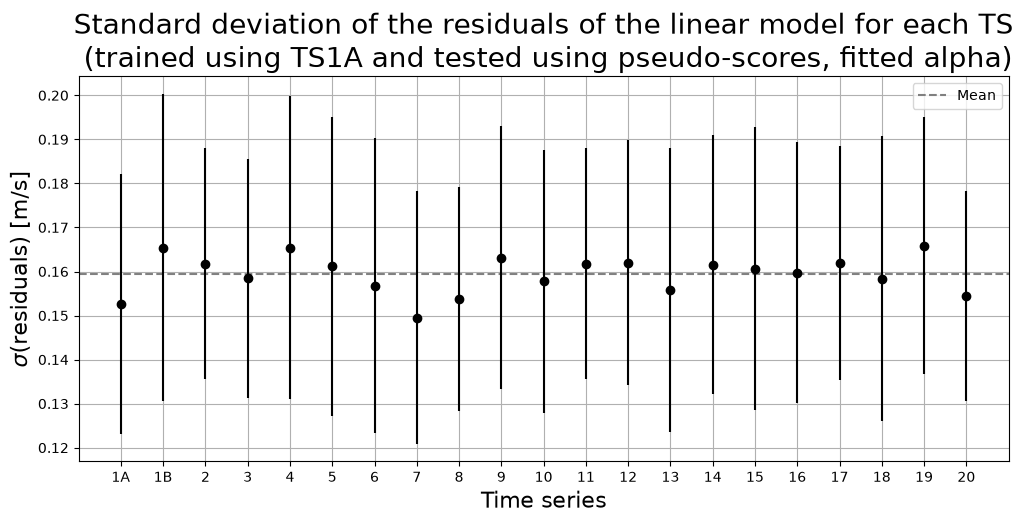

In [25]:
# showing std for each TS
ts_arr = np.linspace(1, N_files + 1, N_files + 1)  # array of integers from 1 to the number of TS (+1 to account for splitting the first TS)

# array of the results for each TS
y = np.mean(res_sigma, axis=1)
y_err = np.std(res_sigma, axis=1)

y = np.delete(y, ts_index)  # taking out reference TS
y_err = np.delete(y_err, ts_index)

y = np.insert(y, ts_index, np.mean(res_sigma_1))  # inserting TSXB results
y_err = np.insert(y_err, ts_index, np.std(res_sigma_1))

y = np.insert(y, ts_index, np.mean(res_sigma_test_0))  # inserting TSXA results
y_err = np.insert(y_err, ts_index, np.std(res_sigma_test_0))

# create a list for xticklabels
xticklabels = []
for i in range(1, N_files + 1):
    if i == ts_index + 1:
        xticklabels.append(f"{i}A")
        xticklabels.append(f"{i}B")
    else:
        xticklabels.append(str(i))

# plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title(f'Standard deviation of the residuals of the linear model for each TS\n (trained using TS{ts_index+1}A and tested using pseudo-scores, fitted alpha)', size=20)

ax.grid()
ax.errorbar(ts_arr, y, y_err, fmt='o', color='k', zorder=2)
#ax.axhspan(np.mean(y) - np.std(y), np.mean(y) + np.std(y), color='gray', alpha=.5)
ax.axhline(np.mean(y), color='gray', linestyle='--', label='Mean', zorder=1)

ax.set_xlabel('Time series', size=16)
ax.set_ylabel(r'$\sigma$(residuals) [m/s]', size=16)

ax.set_xticks(ts_arr)
ax.set_xticklabels(xticklabels)

ax.legend()
plt.show()

In [26]:
# overall sigma_res
print(f'The mean of Sigma(res) over all TS is {np.mean(y):.3f} +- {np.std(y):.3f} m/s.')
print(f'The mean of the error bars is {np.mean(y_err):.3f} m/s.')

The mean of Sigma(res) over all TS is 0.159 +- 0.004 m/s.
The mean of the error bars is 0.030 m/s.


In [27]:
# mean and standard deviation of the residuals (per chunk) for TSXA
print(f'Sigma(res) = {y[ts_index]:.3f} +- {y_err[ts_index]:.3f} m/s.')

Sigma(res) = 0.153 +- 0.030 m/s.


In [28]:
# mean and standard deviation of the residuals (per chunk) for TSXB
print(f'Sigma(res) = {y[ts_index + 1]:.3f} +- {y_err[ts_index + 1]:.3f} m/s.')

Sigma(res) = 0.165 +- 0.035 m/s.
